# PulseIA — Classificador de risco textual (revisão pós-avaliação)

Fase 2 • Grupo PulseIA

Este notebook mantém TF-IDF e Regressão Logística, mas amplia a avaliação e responde ao feedback recebido. As frases e os rótulos são didáticos. A saída do modelo representa confiança estatística dentro destes exemplos — não probabilidade clínica, diagnóstico ou autorização para definir atendimento.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.frozen import FrozenEstimator
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, brier_score_loss, log_loss)

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "fase2/data/frases_risco.csv").exists())
sys.path.insert(0, str(RAIZ / "fase2/src"))
from avaliar_classificador import criar_modelo, prever, metricas_binarias, explicar_frase

SAIDA = RAIZ / "fase2/outputs"
SEED = 42
CLASSES = ["baixo risco", "alto risco"]
dados = pd.read_csv(RAIZ / "fase2/data/frases_risco.csv")
particoes = pd.read_csv(RAIZ / "fase2/data/particoes.csv")
dados = dados.merge(particoes, on="grupo", validate="many_to_one")
display(dados.head())

,frase,situacao,grupo,conjunto
0,Dor no peito começou de repente e estou suando...,alto risco,A01,treino
1,Sinto pressão no tórax acompanhada de suor gel...,alto risco,A01,treino
2,Estou sem ar mesmo sentado e não consigo falar...,alto risco,A02,treino
3,A respiração ficou difícil em repouso e mal co...,alto risco,A02,treino
4,Desmaiei durante a caminhada e continuo muito ...,alto risco,A03,treino


## 1. Composição, diversidade e separação

A base principal passou de 288 para 416 frases balanceadas, em 208 cenários com duas paráfrases. Os novos exemplos incluem fala mais coloquial, atribuição a terceiros, tempo de início, recuperação após esforço, persistência, dupla negação e contradições. Paráfrases do mesmo cenário permanecem sempre no mesmo conjunto.

O antigo teste de 24 frases foi preservado como regressão porque seus erros já eram conhecidos. O novo teste final tem 64 frases (32 cenários), mais que o dobro da versão avaliada. Há ainda 16 frases exclusivas para calibração e 32 cenários externos, derivados de orientações públicas e nunca usados para ajuste. Eles são cenários redigidos para o estudo, não relatos reais.

In [2]:
perfil = dados.groupby(["conjunto", "situacao"]).agg(frases=("frase", "size"), grupos=("grupo", "nunique"))
display(perfil)
assert not dados.frase.str.casefold().str.strip().duplicated().any()
assert dados.groupby("grupo").situacao.nunique().eq(1).all()
conjuntos = {nome: dados[dados.conjunto == nome].copy() for nome in ("treino", "calibracao", "teste", "regressao")}
assert tuple(len(conjuntos[n]) for n in conjuntos) == (256, 16, 64, 80)
for a in conjuntos:
    for b in conjuntos:
        if a < b:
            assert set(conjuntos[a].grupo).isdisjoint(conjuntos[b].grupo)

frases  grupos
conjunto   situacao                   
calibracao alto risco        8       4
           baixo risco       8       4
regressao  alto risco       40      20
           baixo risco      40      20
teste      alto risco       32      16
           baixo risco      32      16
treino     alto risco      128      64
           baixo risco     128      64

## 2. TF-IDF e seleção no treino

O pré-processamento acrescenta marcadores para negação, dupla negação, contradição, recuperação completa, persistência, esforço, repouso e relato de terceiros. Ele continua sendo uma regra limitada, não um interpretador da língua portuguesa.

A validação cruzada estratificada mantém os grupos de paráfrases juntos. Comparamos bigramas/trigramas, duas intensidades de regularização e pesos de classe. O teste final não participa da seleção.

In [3]:
treino = conjuntos["treino"]
cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
busca = GridSearchCV(criar_modelo(), {
    "tfidf__ngram_range": [(1, 2), (1, 3)],
    "classificador__C": [1.0, 4.0],
    "classificador__class_weight": [None, "balanced"],
}, cv=cv, scoring={"acuracia": "accuracy", "f1_macro": "f1_macro"}, refit="f1_macro")
busca.fit(treino.frase, treino.situacao, groups=treino.grupo)
modelo_base = busca.best_estimator_
comparacao = pd.DataFrame(busca.cv_results_)
display(comparacao[["params", "mean_test_acuracia", "mean_test_f1_macro", "std_test_f1_macro"]])
print("Configuração selecionada:", busca.best_params_)

,params,mean_test_acuracia,mean_test_f1_macro,std_test_f1_macro
0,"{'classificador__C': 1.0, 'classificador__clas...",0.929688,0.929670,0.034062
1,"{'classificador__C': 1.0, 'classificador__clas...",0.933594,0.933583,0.030007
2,"{'classificador__C': 1.0, 'classificador__clas...",0.929688,0.929670,0.034062
3,"{'classificador__C': 1.0, 'classificador__clas...",0.933594,0.933583,0.030007
4,"{'classificador__C': 4.0, 'classificador__clas...",0.941406,0.941380,0.033839
5,"{'classificador__C': 4.0, 'classificador__clas...",0.937500,0.937494,0.029233
6,"{'classificador__C': 4.0, 'classificador__clas...",0.941406,0.941380,0.033839
7,"{'classificador__C': 4.0, 'classificador__clas...",0.937500,0.937494,0.029233


Configuração selecionada: {'classificador__C': 4.0, 'classificador__class_weight': None, 'tfidf__ngram_range': (1, 2)}


## 3. Calibração e interpretação das probabilidades

A Regressão Logística produz escores entre 0 e 1. Eles não medem risco médico. Uma calibração sigmoide foi ajustada em 16 frases separadas do treino e do teste. Comparamos Brier score, log loss e curva de confiabilidade. A amostra de calibração ainda é pequena, por isso os valores servem apenas para investigar o comportamento do modelo.

,modelo,Brier,log loss
0,sem calibração,0.127228,0.424621
1,calibração sigmoide,0.105183,0.339971


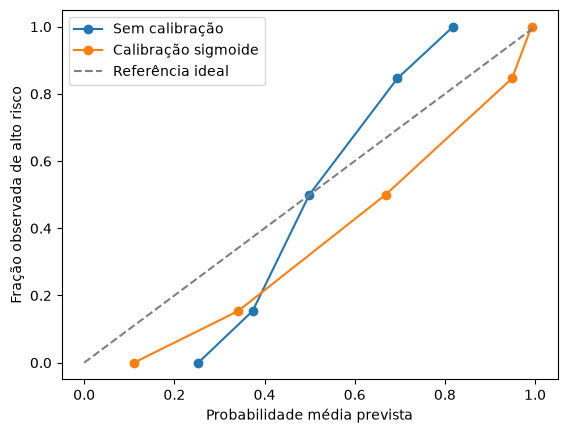

In [4]:
calibrado = CalibratedClassifierCV(FrozenEstimator(modelo_base), method="sigmoid")
calibrado.fit(conjuntos["calibracao"].frase, conjuntos["calibracao"].situacao)
teste = conjuntos["teste"].copy()
teste["predicao"], teste["probabilidade_alto_risco"] = prever(calibrado, teste.frase)
teste["acerto"] = teste.situacao == teste.predicao
y = (teste.situacao == "alto risco").astype(int).to_numpy()
p_base = modelo_base.predict_proba(teste.frase)[:, list(modelo_base.classes_).index("alto risco")]
p_cal = teste.probabilidade_alto_risco.to_numpy()
comparacao_calibracao = pd.DataFrame([
    {"modelo": "sem calibração", "Brier": brier_score_loss(y, p_base), "log loss": log_loss(y, p_base)},
    {"modelo": "calibração sigmoide", "Brier": brier_score_loss(y, p_cal), "log loss": log_loss(y, p_cal)},
])
display(comparacao_calibracao)
for prob, nome in ((p_base, "Sem calibração"), (p_cal, "Calibração sigmoide")):
    observado, previsto = calibration_curve(y, prob, n_bins=5, strategy="quantile")
    plt.plot(previsto, observado, marker="o", label=nome)
plt.plot([0, 1], [0, 1], "--", color="gray", label="Referência ideal")
plt.xlabel("Probabilidade média prevista"); plt.ylabel("Fração observada de alto risco")
plt.legend(); plt.show()

## 4. Teste final ampliado

Relatamos acurácia, precisão, recall, F1 e matriz de confusão. Os erros permanecem listados. Como o teste tem 64 frases sintéticas e já foi observado nesta revisão, ele não valida uso clínico nem deve ser reutilizado como teste independente depois de orientar mudanças futuras.

,precision,recall,f1-score,support
baixo risco,0.931034,0.843750,0.885246,32.000000
alto risco,0.857143,0.937500,0.895522,32.000000
accuracy,0.890625,0.890625,0.890625,0.890625
macro avg,0.894089,0.890625,0.890384,64.000000
weighted avg,0.894089,0.890625,0.890384,64.000000


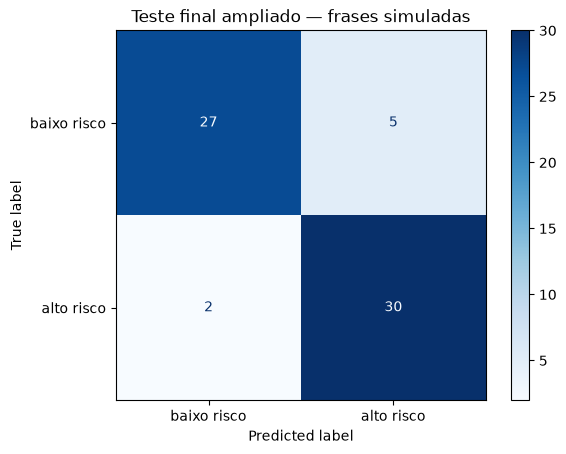

,frase,situacao,predicao,probabilidade_alto_risco
327,"Depois da cafeína vieram palpitações, aperto t...",alto risco,baixo risco,0.385487
351,"Achei que fosse músculo, mas apertar o local n...",alto risco,baixo risco,0.442422
388,Senti o coração bater forte durante um susto e...,baixo risco,alto risco,0.746612
390,"A queimação veio após uma refeição grande, mel...",baixo risco,alto risco,0.727214
392,"O ombro dói quando levanto peso, mas não há do...",baixo risco,alto risco,0.952100
394,Minha fala ficou estranha porque mordi a língu...,baixo risco,alto risco,0.899465
410,Tenho falta de ar somente quando prendo volunt...,baixo risco,alto risco,0.794955


In [5]:
display(pd.DataFrame(classification_report(teste.situacao, teste.predicao, labels=CLASSES, output_dict=True, zero_division=0)).T)
matriz = confusion_matrix(teste.situacao, teste.predicao, labels=CLASSES)
ConfusionMatrixDisplay(matriz, display_labels=CLASSES).plot(cmap="Blues")
plt.title("Teste final ampliado — frases simuladas"); plt.show()
display(teste[~teste.acerto][["frase", "situacao", "predicao", "probabilidade_alto_risco"]])

## 5. Erros e os dois falsos positivos da versão avaliada

As duas paráfrases de `B69` — suor após academia com recuperação — foram falsos positivos na entrega avaliada. Agora elas ficam na regressão. O arquivo `investigacao_erros.csv` registra os termos que mais deslocam a decisão de cada erro e mostra que B69 passou a ser classificado corretamente. Essas contribuições explicam matematicamente o modelo linear; não são causas clínicas.

In [6]:
regressao = conjuntos["regressao"].copy()
regressao["predicao"], regressao["probabilidade_alto_risco"] = prever(calibrado, regressao.frase)
regressao["acerto"] = regressao.situacao == regressao.predicao
display(regressao[regressao.grupo == "B69"])
explicacoes = []
for _, linha in teste[~teste.acerto].iterrows():
    positivos, negativos = explicar_frase(modelo_base, linha.frase)
    explicacoes.append({"frase": linha.frase, "termos que favorecem alto risco": positivos,
                        "termos que favorecem baixo risco": negativos})
display(pd.DataFrame(explicacoes))

,frase,situacao,grupo,conjunto,predicao,probabilidade_alto_risco,acerto
280,"Suei bastante na academia, parei, bebi água e ...",baixo risco,B69,regressao,baixo risco,0.232829,True
281,O suor veio do treino e já passou; meu coração...,baixo risco,B69,regressao,baixo risco,0.187535,True


,frase,termos que favorecem alto risco,termos que favorecem baixo risco
0,"Depois da cafeína vieram palpitações, aperto t...",depois (0.333) | da (0.242) | aperto toracico ...,quase (-0.255) | desmaiei (-0.197)
1,"Achei que fosse músculo, mas apertar o local n...",mas (0.145) | apertar (0.101) | local (0.100) ...,dor (-0.171)
2,Senti o coração bater forte durante um susto e...,depois (0.455) | um (0.228) | logo (0.146) | s...,forte (-0.508) | coracao (-0.277) | durante (-...
3,"A queimação veio após uma refeição grande, mel...",apos (0.368) | ao (0.278) | neg_suor_frio (0.1...,frio (-0.269) | veio (-0.257) | suor (-0.246) ...
4,"O ombro dói quando levanto peso, mas não há do...",neg_sintoma_toracico (0.246) | mas nao (0.206),peito (-0.192) | em repouso (-0.156) | repouso...
5,Minha fala ficou estranha porque mordi a língu...,normal (0.146) | esta (0.111),dos (-0.142) | forca (-0.127) | bracos (-0.124...
6,Tenho falta de ar somente quando prendo volunt...,tenho (0.123) | na (0.098) | somente (0.086),ar (-0.239) | respiracao (-0.114) | tenho falt...


## 6. Avaliação externa e pares de gravidade

A avaliação externa contém 32 cenários derivados de páginas do Ministério da Saúde e da OMS, com fonte por linha. Eles não foram usados no treino, na seleção ou na calibração. Não são transcrições de pacientes nem padrão-ouro validado.

Os 16 pares contrastam vocabulário semelhante em manifestações graves versus leves ou resolvidas. Esse teste torna visível quando o modelo se apoia em palavras isoladas e ignora duração, persistência, esforço ou recuperação.

In [7]:
def avaliar_arquivo(nome):
    df = pd.read_csv(RAIZ / "fase2/data" / nome)
    df["predicao"], df["probabilidade_alto_risco"] = prever(calibrado, df.frase)
    df["acerto"] = df.situacao == df.predicao
    return df, metricas_binarias(df.situacao, df.predicao)
externo, met_externo = avaliar_arquivo("avaliacao_externa.csv")
pares, met_pares = avaliar_arquivo("pares_gravidade.csv")
display(pd.DataFrame([{"conjunto": "externo", **met_externo}, {"conjunto": "pares", **met_pares}]))
display(externo[~externo.acerto][["id", "frase", "situacao", "predicao", "fonte"]])

,conjunto,n,acuracia,precisao_alto_risco,recall_alto_risco,f1_macro,falsos_negativos,falsos_positivos,matriz_confusao
0,externo,32,0.84375,0.761905,1.0,0.83984,0,5,"[[11, 5], [0, 16]]"
1,pares,32,0.84375,0.761905,1.0,0.83984,0,5,"[[11, 5], [0, 16]]"


,id,frase,situacao,predicao,fonte
16,E17,A dor aparece quando aperto exatamente o múscu...,baixo risco,alto risco,https://linhasdecuidado.saude.gov.br/portal/do...
21,E22,A palpitação aconteceu no susto e desapareceu ...,baixo risco,alto risco,https://www.who.int/health-topics/cardiovascul...
24,E25,"A queimação veio após comer e melhorou, sem pa...",baixo risco,alto risco,https://www.gov.br/saude/pt-br/assuntos/saude-...
27,E28,Ontem neguei dor e hoje continuo sem qualquer ...,baixo risco,alto risco,https://linhasdecuidado.saude.gov.br/portal/do...
29,E30,A marca da roupa no peito sumiu assim que afro...,baixo risco,alto risco,https://linhasdecuidado.saude.gov.br/portal/do...


## 7. Auditoria sintética de subgrupos

Doze cenários idênticos foram combinados com sexo referido e duas faixas etárias, formando 48 casos pareados. Comparamos acurácia, recall e falsos positivos por grupo. Diferença zero neste teste significa apenas que trocar essas palavras não mudou as previsões. Não demonstra fairness: faltam dados reais, interseccionalidade, prevalências e desfechos por população.

In [8]:
subgrupos, _ = avaliar_arquivo("avaliacao_subgrupos.csv")
linhas = []
for dimensao in ("sexo_referido", "faixa_etaria"):
    for valor, grupo in subgrupos.groupby(dimensao):
        linhas.append({"dimensao": dimensao, "grupo": valor, **metricas_binarias(grupo.situacao, grupo.predicao)})
display(pd.DataFrame(linhas))

,dimensao,grupo,n,acuracia,precisao_alto_risco,recall_alto_risco,f1_macro,falsos_negativos,falsos_positivos,matriz_confusao
0,sexo_referido,homem,24,1.0,1.0,1.0,1.0,0,0,"[[12, 0], [0, 12]]"
1,sexo_referido,mulher,24,1.0,1.0,1.0,1.0,0,0,"[[12, 0], [0, 12]]"
2,faixa_etaria,idosa,24,1.0,1.0,1.0,1.0,0,0,"[[12, 0], [0, 12]]"
3,faixa_etaria,jovem,24,1.0,1.0,1.0,1.0,0,0,"[[12, 0], [0, 12]]"


## 8. Validação clínica e limites

As 83 associações do mapa passaram por uma triagem documental, registrada em `data/revisao_clinica.csv`. A coluna de validação especializada permanece `pendente`. Somente um profissional habilitado, identificado com registro e data, poderá preencher essa etapa. Fonte pública e revisão do grupo não substituem validação clínica.

Conclusão: a revisão amplia diversidade, teste, rastreabilidade e análise de erros. Ela também encontra limites novos, sobretudo falsos positivos em frases leves que compartilham vocabulário com alertas. Esses resultados são mais informativos que uma acurácia isolada.

## Fontes metodológicas e clínicas

- [Scikit-learn — calibração de probabilidades](https://scikit-learn.org/stable/modules/calibration.html)
- [Ministério da Saúde — infarto](https://www.gov.br/saude/pt-br/assuntos/saude-de-a-a-z/i/infarto)
- [Linha de Cuidado do Ministério da Saúde — dor torácica](https://linhasdecuidado.saude.gov.br/portal/dor-toracica/unidade-de-atencao-primaria/manejo-inicial/)
- [OMS — doenças cardiovasculares](https://www.who.int/health-topics/cardiovascular-diseases)
- [Protocolo e fontes do projeto](../docs/validacao_clinica.md)